# What makes a pitch effective?

A Stuff+ model for player development. The grade uses only the flight of the ball: velocity, spin, movement, release, extension, approach angles, and the gap from the pitcher's own fastball. Location, count, and the hitter are left out on purpose. Those are command and sequencing. This is the shape.

100 is league average for that pitch type. Ten points is one standard deviation of pitcher-season means. Higher is better for the pitcher.

The sections below are the interview walkthrough: the data, the physics, the holdout, the grade, how fast it stabilizes, and what a Marlins development memo would actually say.

In [1]:
from pathlib import Path
import json
import sys

import duckdb
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from stuffplus.config import FEATURE_LABELS, PITCH_NAMES, RAW_DIR, FIGURE_DIR, PROCESSED_DIR
from stuffplus.physics import approach_angles, arm_side_break, induced_vertical_break

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
metrics = json.loads((PROCESSED_DIR / "metrics.json").read_text())
print("Modeling pitches:", f"{metrics['modeling_pitches']:,}")
print("By season:", metrics["modeling_pitches_by_season"])

Modeling pitches: 2,124,073
By season: {'2024': 706500, '2025': 706380, '2026': 711193}


## The data

Regular-season Statcast, pulled with `pybaseball.statcast` from Baseball Savant and cached as parquet. The inventory query is plain SQL in DuckDB. Spring training and the postseason are not in the file. The model trains on 2024 and 2025 and is graded on 2026. A second model trains on 2024 only, so 2025 and 2026 can be compared without either year having been in the fit.

In [2]:
inventory = duckdb.connect().execute(f'''
    SELECT game_year AS season,
           COUNT(*) AS pitches,
           COUNT(DISTINCT pitcher) AS pitchers,
           MIN(game_date) AS first_date,
           MAX(game_date) AS last_date
    FROM read_parquet('{(RAW_DIR / "pitches_*.parquet").as_posix()}')
    GROUP BY 1
    ORDER BY 1
''').fetchdf()
inventory

,season,pitches,pitchers,first_date,last_date
0,2024,711899,855,2024-03-20,2024-09-30
1,2025,712528,873,2025-03-18,2025-09-28
2,2026,716792,868,2026-03-25,2026-09-27


## One pitch, from the tracking fit to a grade

Statcast publishes the acceleration fit (`vx0, vy0, vz0, ax, ay, az`) and the movement relative to a spinless pitch (`pfx_x`, `pfx_z`). Induced vertical break is `pfx_z` in inches. Horizontal break is mirrored so positive means arm side for a left-hander and a right-hander. Approach angle is the direction of the velocity vector at the front of the plate, which is 17 inches from the coordinate origin. Savant's `attack_angle` column is the batter's swing, not the pitch, so it is not used.

The cell below recomputes break and vertical approach angle for one tracked pitch and shows the same functions the model uses.

In [3]:
example = duckdb.connect().execute(f'''
    SELECT pitch_type, p_throws, release_speed, pfx_x, pfx_z,
           vx0, vy0, vz0, ax, ay, az, release_pos_y, arm_angle
    FROM read_parquet('{(RAW_DIR / "pitches_2026.parquet").as_posix()}')
    WHERE pitch_type = 'FF' AND p_throws = 'R' AND release_speed BETWEEN 95 AND 97
    LIMIT 1
''').fetchdf().iloc[0]

ivb = float(induced_vertical_break(example.pfx_z))
hb = float(arm_side_break(example.pfx_x, example.p_throws))
_, vaa, _ = approach_angles(
    example.vx0, example.vy0, example.vz0,
    example.ax, example.ay, example.az, example.release_pos_y,
)
print(f"{example.p_throws}HP {example.pitch_type} at {example.release_speed:.1f} mph")
print(f"Induced vertical break {ivb:.1f} in, arm-side break {hb:.1f} in")
print(f"Vertical approach angle {float(vaa):.2f} degrees (negative means downhill)")
print(f"Measured arm angle {example.arm_angle:.1f} degrees")
diag = metrics["diagnostics"]
print(
    f"On the full sample, this arm-side break matches Savant at r = "
    f"{diag['arm_side_break_vs_savant_correlation']:.3f}."
)
print(
    f"A shoulder-free arm-angle proxy correlates "
    f"{diag['arm_angle_proxy_correlation']:.2f} with the measurement "
    f"(MAE {diag['arm_angle_proxy_mae_degrees']:.1f} degrees), so the model uses the measurement."
)

RHP FF at 96.4 mph
Induced vertical break 15.0 in, arm-side break 9.4 in
Vertical approach angle -5.00 degrees (negative means downhill)
Measured arm angle 39.7 degrees
On the full sample, this arm-side break matches Savant at r = 1.000.
A shoulder-free arm-angle proxy correlates 0.72 with the measurement (MAE 19.2 degrees), so the model uses the measurement.


## Did shape beat the pitch label?

Three baselines sit under the gradient-boosted model. The league mean says every pitch is average. The pitch-type mean uses the official label, which Stuff+ is not allowed to see. Ridge regression is the linear reading of the same physical features. LightGBM is the grade.

Pitch-level R² on run value is supposed to be small. A single pitch outcome is the hitter, the count, and a lot of luck. The honest test is whether the prediction still lines up after it is averaged to a pitcher and a pitch type, and whether it lines up inside one pitch type, where the label has nothing left to say.

Run value here is count-neutral. Each outcome (whiff, called strike, foul, ball, single, home run, and so on) is worth the training-set average of `delta_run_exp` for that outcome. The count the pitch happened to be thrown in does not enter the target.

In [4]:
def line(block, name):
    agg = block["aggregated_min_100"]
    return {
        "model": name,
        "pitch_r2": round(block["r2"], 4),
        "pitch_rmse": round(block["rmse"], 4),
        "pitcher_pitch_r": None if agg["corr"] is None else round(agg["corr"], 3),
        "groups": agg["groups"],
    }

for label, key in [
    ("2025, trained on 2024", "holdout_2025_trained_on_2024"),
    ("2026, trained on 2024-2025", "holdout_2026_trained_on_2024_2025"),
]:
    block = metrics[key]
    print(label, "trees", block["best_iteration"])
    rows = [line(block["metrics"][name], name) for name in ("league_mean", "pitch_type_mean", "ridge", "lightgbm")]
    display(pd.DataFrame(rows))

whiff = metrics["whiff_model_2026"]
print(
    f"Whiff model on 2026 swings: AUC {whiff['auc']:.3f}, "
    f"Brier {whiff['brier']:.4f}, log loss {whiff['log_loss']:.4f}, "
    f"calibration error {whiff['ece']:.4f}, base rate {whiff['base_rate']:.3f}."
)
print(
    "Correlation of run-value Stuff+ and the whiff grade, "
    f"pitcher-pitch-seasons with 100+ pitches: {metrics['stuff_plus_vs_whiff_grade_correlation']:.3f}."
)

2025, trained on 2024 trees 272


,model,pitch_r2,pitch_rmse,pitcher_pitch_r,groups
0,league_mean,-0.0000,0.2100,-0.004,1938
1,pitch_type_mean,0.0000,0.2100,0.071,1938
2,ridge,0.0001,0.2100,0.119,1938
3,lightgbm,0.0136,0.2086,0.225,1938


2026, trained on 2024-2025 trees 583


,model,pitch_r2,pitch_rmse,pitcher_pitch_r,groups
0,league_mean,-0.0000,0.2086,-0.000,1986
1,pitch_type_mean,0.0000,0.2086,0.074,1986
2,ridge,-0.0001,0.2086,0.137,1986
3,lightgbm,0.0157,0.2069,0.280,1986


Whiff model on 2026 swings: AUC 0.752, Brier 0.1535, log loss 0.4764, calibration error 0.0041, base rate 0.252.
Correlation of run-value Stuff+ and the whiff grade, pitcher-pitch-seasons with 100+ pitches: 0.296.


## Calibration

If the model says a bin of pitches should be worth a given run value, the bin should come in near that number. The same check on the whiff model is a probability: predicted whiff rate against actual whiff rate. A model can rank pitches and still be miscalibrated. Both charts are the 2026 holdout.

**calibration_rv.png**

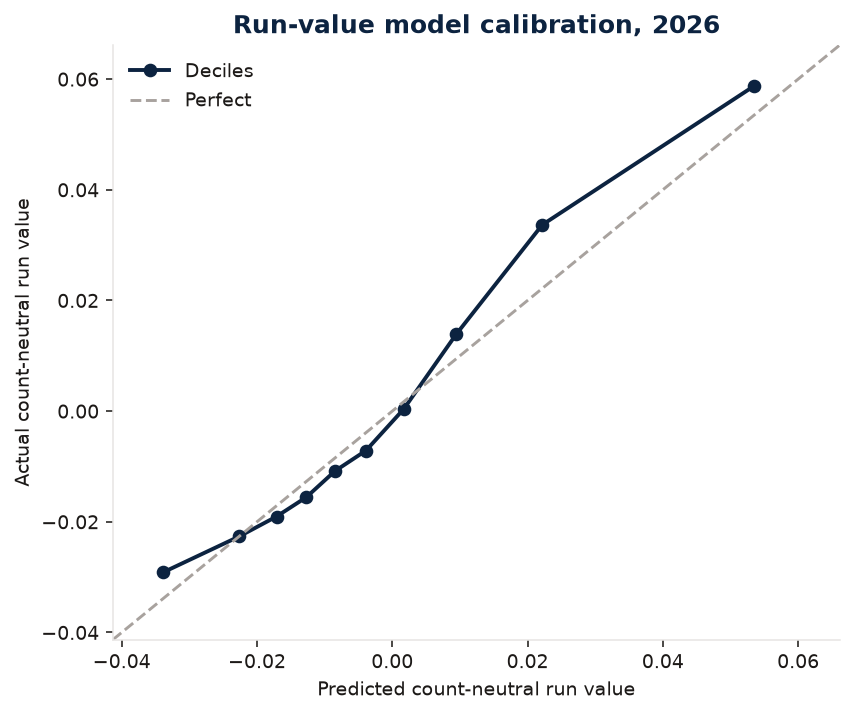

**calibration_whiff.png**

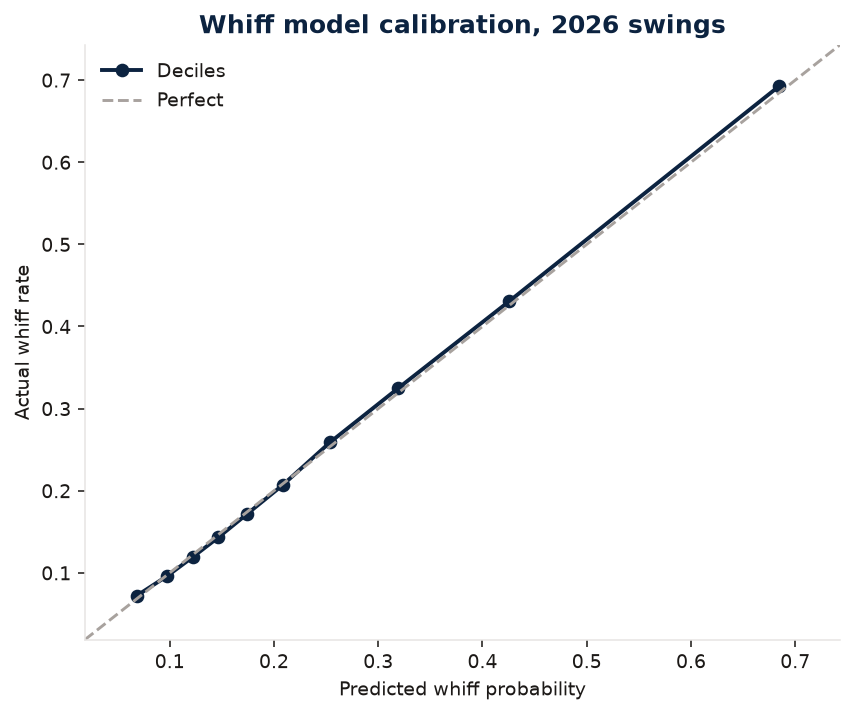

In [5]:
for name in ["calibration_rv.png", "calibration_whiff.png"]:
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(FIGURE_DIR / name)))

## What the model uses

SHAP values are the contribution of each feature to a pitch's predicted run value, in run-value units. Mean absolute SHAP is the average size of that contribution on a 2026 sample. Positive run value is good for the hitter, so a feature that lowers predicted run value is a better pitch. The fastball gaps are in the model because an 85 mph slider is a different pitch under a 98 mph four-seamer than under a 92 mph sinker.

,mean_abs_shap
"Horizontal approach angle, arm side (deg)",0.00850
Vertical approach angle (deg),0.00727
Arm-side break (in),0.00545
Induced vertical break (in),0.00478
"Horizontal release, arm side (ft)",0.00447
Velocity (mph),0.00287
Velocity vs primary fastball (mph),0.00286
Release height (ft),0.00246
IVB vs primary fastball (in),0.00168
"Movement per 1,000 rpm (in)",0.00156


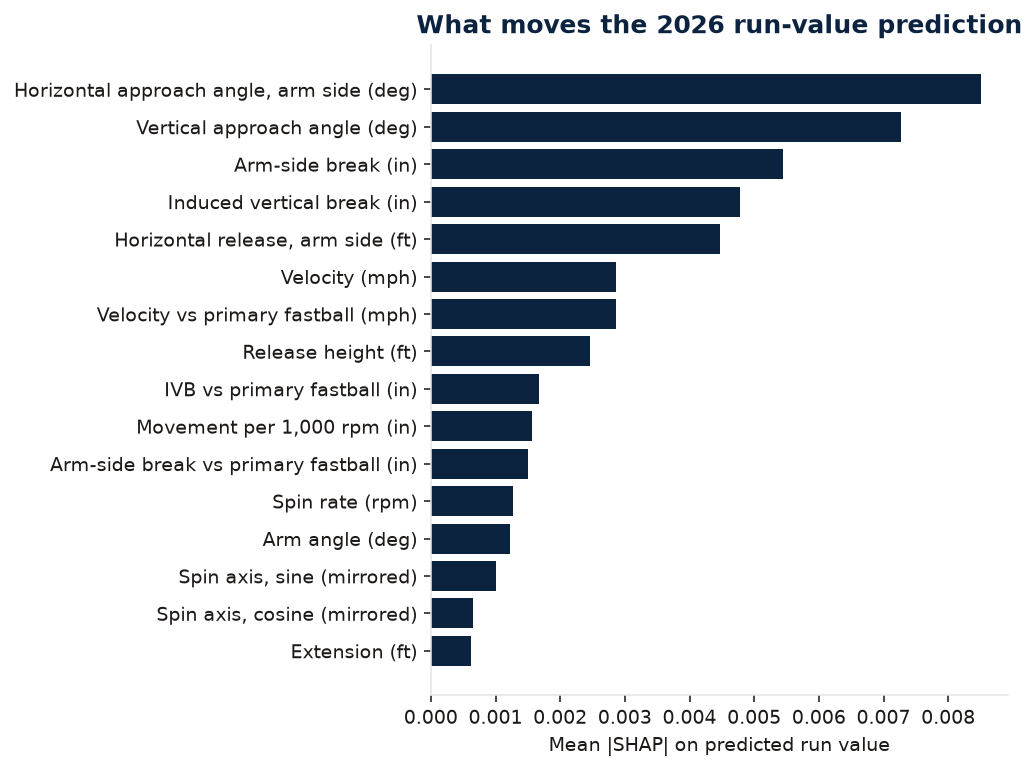

In [6]:
shap_table = (
    pd.Series(metrics["shap"]["mean_abs_shap"])
    .rename("mean_abs_shap")
    .sort_values(ascending=False)
    .rename(index=FEATURE_LABELS)
    .to_frame()
)
shap_table["mean_abs_shap"] = shap_table["mean_abs_shap"].round(5)
display(shap_table)
display(Image(filename=str(FIGURE_DIR / "shap_summary.png")))

## Clusters

Official pitch labels are a codebook. The mixture model only sees velocity, induced vertical break, arm-side break, and spin, and it chooses the number of groups by BIC. The adjusted Rand index against the official label says how much of the codebook the shape space rediscovers. Peer recommendations use the fastball's cluster: pitchers with a similar fastball, and the secondary pitches they throw that this pitcher does not.

k = 12, BIC-selected. Adjusted Rand vs pitch type = 0.426.


,cluster,pitches,majority_pitch,majority_share,velo,ivb,hb_arm,spin,stuff_plus
0,3,91828,CH,0.72,86.93,4.01,14.59,1817.99,100.05
1,9,19483,CU,0.58,83.82,-9.74,-5.66,2583.18,100.25
2,2,10026,CU,0.73,79.57,-10.40,-14.75,2944.40,102.53
3,11,19507,CU,0.36,78.63,-2.50,-10.17,2247.07,97.37
4,6,16818,CU,0.80,78.48,-14.40,-9.41,2618.23,98.97
5,8,69375,FC,0.64,90.14,7.90,-1.79,2376.40,99.38
6,1,211191,FF,0.93,94.91,16.01,7.68,2322.06,101.71
7,7,22712,FS,0.50,85.10,2.87,8.59,1208.07,98.57
8,5,111229,SI,0.84,94.49,8.02,15.61,2218.50,100.64
9,4,46871,SL,0.73,87.29,0.87,-4.89,2607.21,104.93


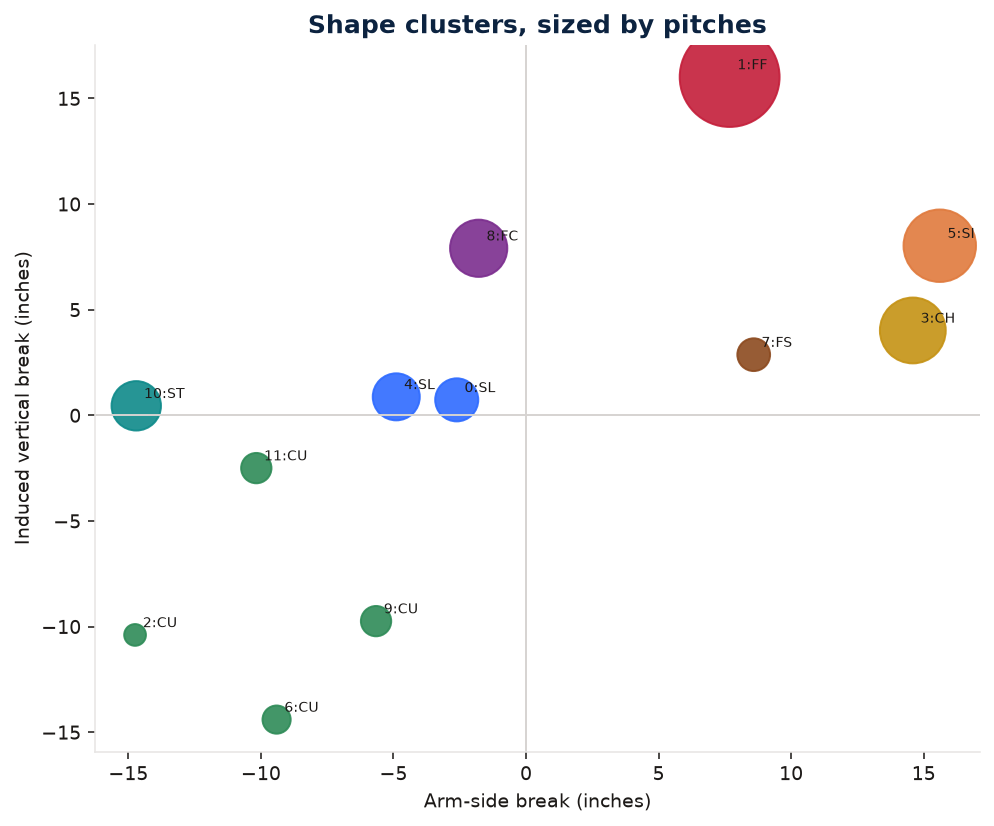

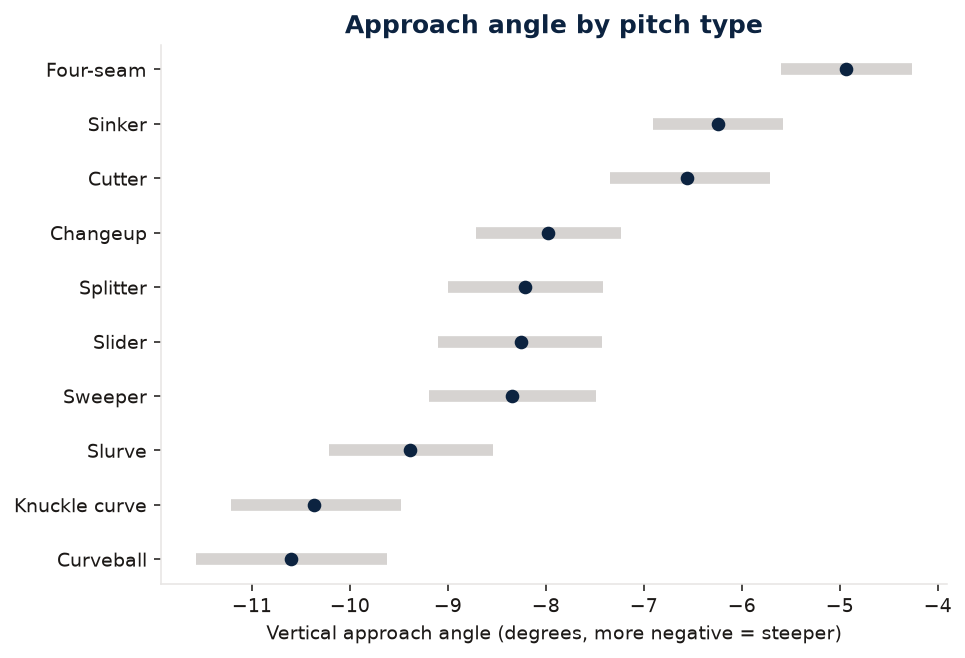

In [7]:
cluster = metrics["clustering"]
print(f"k = {cluster['k']}, BIC-selected. Adjusted Rand vs pitch type = {cluster['adjusted_rand_vs_pitch_type']:.3f}.")
display(pd.read_csv(PROCESSED_DIR / "cluster_profiles.csv").round(2).head(15))
display(Image(filename=str(FIGURE_DIR / "cluster_movement.png")))
display(Image(filename=str(FIGURE_DIR / "vaa_by_pitch_type.png")))

## Reliability

Split-half correlation is the agreement between two random samples of the same size from the same pitcher. That is the reliability of a sample that size. Year-over-year correlation is the same idea with a season on each side. ERA and FIP only exist as season lines, so they get the second test. Stuff+ for that test comes from the model trained only on 2024, applied to both 2025 and 2026, so neither grade was fit on its own season.

The Spearman-Brown formula is a cross-check. It assumes each extra pitch adds independent information. The empirical curve is the result to quote. The formula is there so an interview can show the assumption.

,measure,n,pearson,pitchers
0,Stuff+,25,0.612,769
1,Stuff+,50,0.683,720
2,Stuff+,75,0.706,677
3,Stuff+,100,0.746,634
4,Stuff+,150,0.803,562
5,Stuff+,200,0.841,510
6,Stuff+,300,0.882,422
7,Stuff+,500,0.919,265
8,Stuff+,800,0.942,147
9,Stuff+,1000,0.955,105


Spearman-Brown cross-check


,r_at_100,single_observation_reliability,n_for_0_70,empirical_n_for_0_70
Stuff+,0.746229,0.028566,79.349852,75.0
Whiff rate,0.485056,0.009332,247.710401,300.0
Actual run value,0.069156,0.000742,3140.698137,NaN


,n,pearson,spearman
stuff_plus_min_200,445.0,0.778122,0.751399
whiff_rate_min_150_swings,385.0,0.710616,0.698827
era_min_40_ip,256.0,0.209376,0.217097
fip_min_40_ip,256.0,0.449122,0.428276
k_pct_min_40_ip,256.0,0.700627,0.672858
era_min_80_ip,106.0,0.257145,0.229207
fip_min_80_ip,106.0,0.518684,0.511338
k_pct_min_80_ip,106.0,0.681315,0.630934


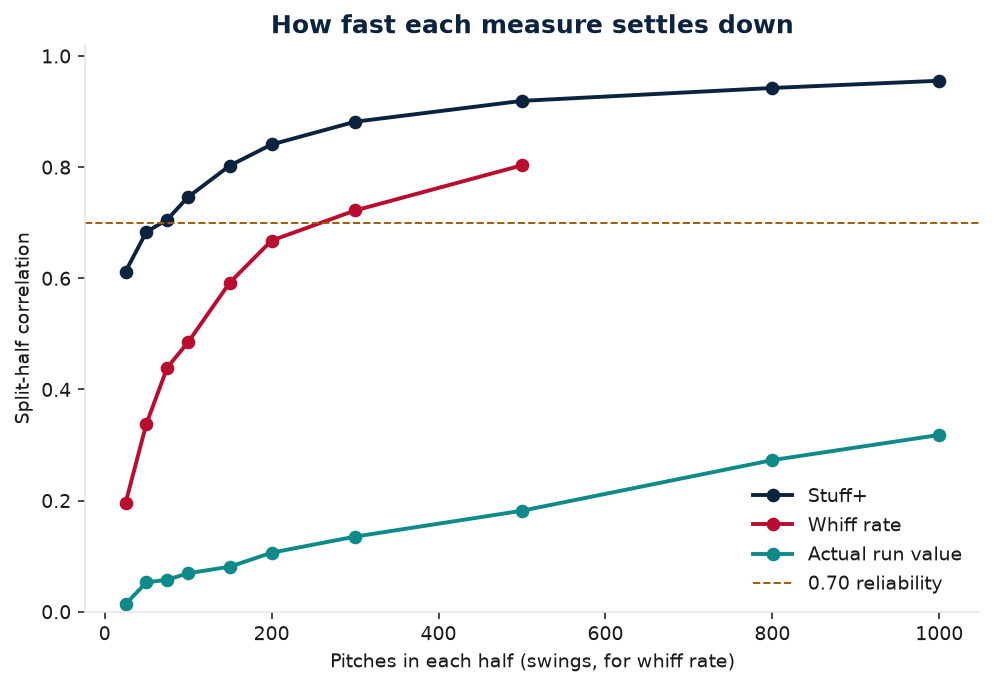

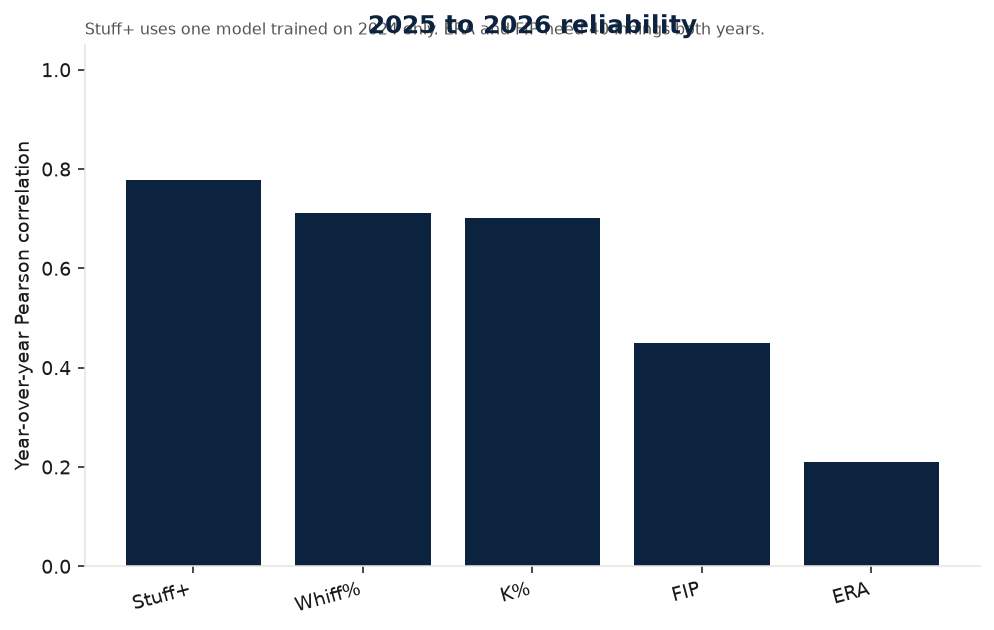

In [8]:
reliability = json.loads((PROCESSED_DIR / "reliability.json").read_text())
rows = []
for name, curve in reliability["split_half"]["curves"].items():
    for point in curve:
        if point["pearson"] is None:
            continue
        rows.append({"measure": name, "n": point["n"], "pearson": round(point["pearson"], 3), "pitchers": point["pitchers"]})
display(pd.DataFrame(rows))
print("Spearman-Brown cross-check")
display(pd.DataFrame(reliability["split_half"]["spearman_brown"]).T)
yoy = pd.DataFrame(reliability["year_over_year"]).T
display(yoy)
display(Image(filename=str(FIGURE_DIR / "reliability_curves.png")))
display(Image(filename=str(FIGURE_DIR / "reliability_yoy.png")))

## Player development

The scatter is arsenal Stuff+ against runs prevented per 100 pitches versus the league. Up and to the right is good shape and good results. Right and down is the development list: the ball is better than the line. The memo pitcher is marked. Suggestions in the app are the same function as the memo: a usage shift with a run estimate, a shape target taken from same-handed pitches in the same velocity band that grade 110 or better, or a pitch type that peer fastballs usually carry and this arsenal does not.

John King 2026 Stuff+ 91.8 pitches 711
Model RV/100 0.40, actual RV/100 -0.77, gap (actual minus model) -1.17


,pitch,pitches,usage,velo,ivb,hb_arm,vaa,whiff_rate,stuff_plus,pred_rv_per_100,actual_rv_per_100
0,Changeup,142,20.0,83.82,-0.39,13.50,-8.70,34.2,92.8,0.49,-2.69
1,Curveball,82,11.5,79.02,-11.91,-11.46,-10.65,7.1,97.5,0.18,4.73
2,Four-seam,9,1.3,90.50,10.32,6.17,-5.12,0.0,26.1,4.63,18.39
3,Sinker,228,32.1,90.45,1.88,12.65,-6.97,16.8,88.9,0.66,-1.55
4,Slider,136,19.1,82.60,-0.66,-6.84,-8.61,20.0,92.1,0.18,-0.87
5,Sweeper,114,16.0,81.49,-1.03,-15.51,-8.75,23.1,97.2,-0.14,-2.13



Results are ahead of the shape grade
Usage-weighted Stuff+ is 92, and results were 1.17 runs per 100 pitches better than the shape model expected. Treat the ERA as fragile until the locations or the pitch mix explain it. Do not redesign a pitch that is already carrying the staff line.

Shape target for the changeup
This changeup averages 83.8 mph, -0.4 in IVB, 13.5 in arm-side break, Stuff+ 93. Same-handed versions within 2 to 4 mph that grade 110 or better (9 pitcher-seasons) sit near 84.8 mph, 4.1 in IVB, 14.2 in arm-side break, median Stuff+ 114. The gap is 4.5 in more ride. That is a bullpen target, not a promise that closing the gap adds 21 points.


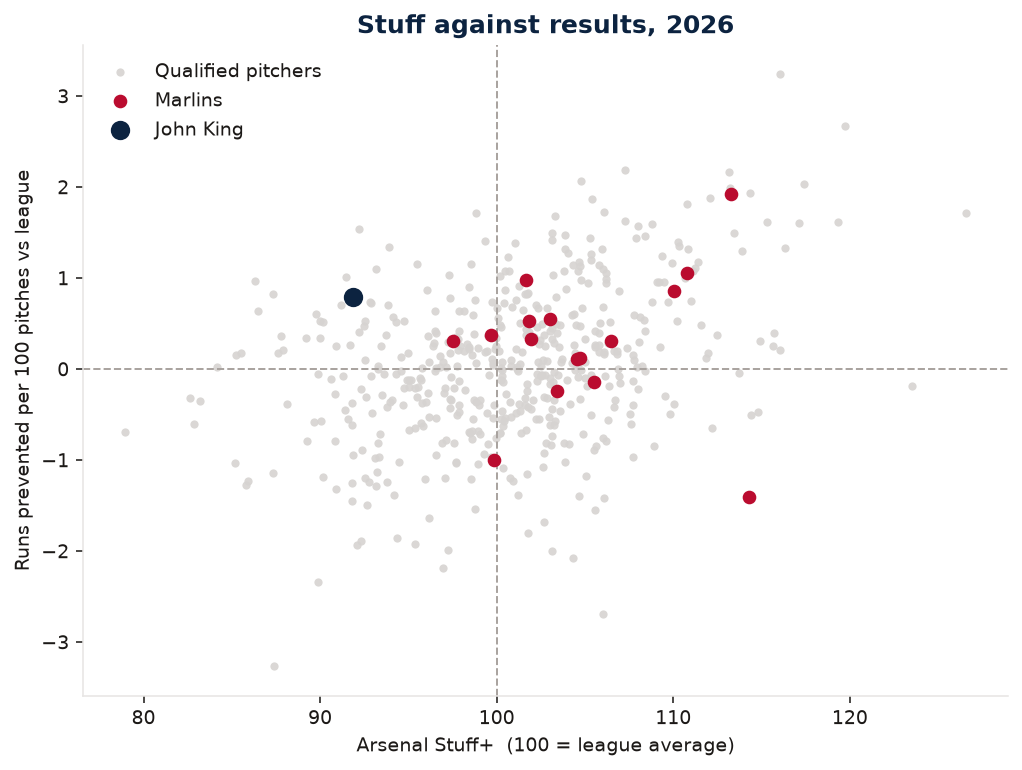

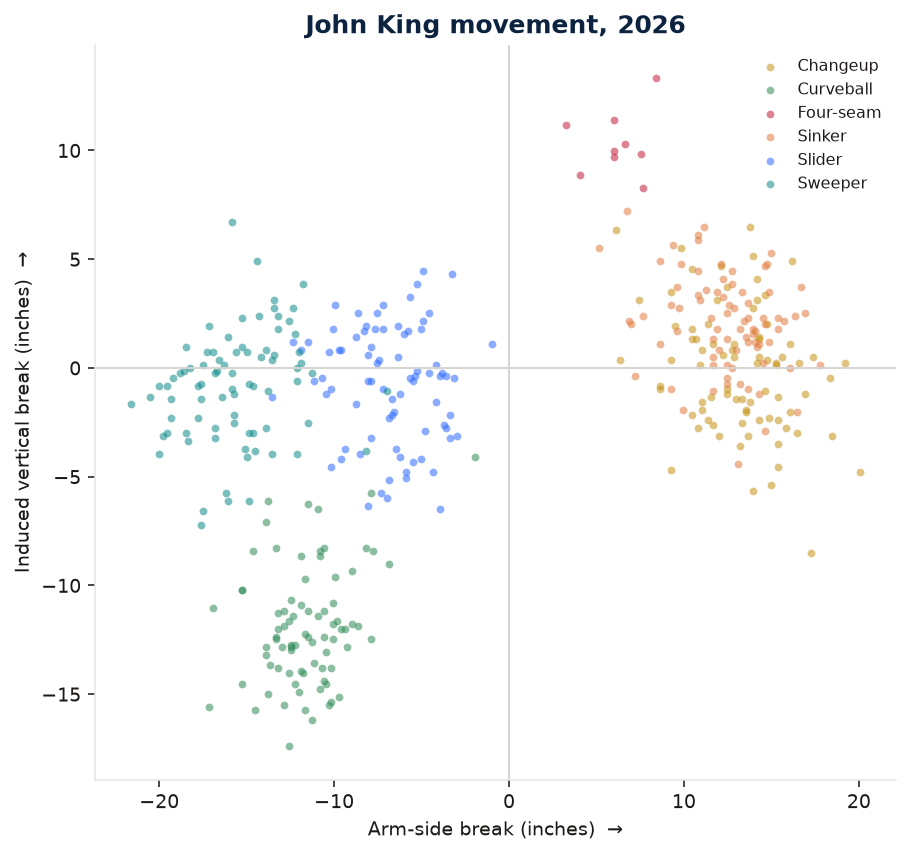

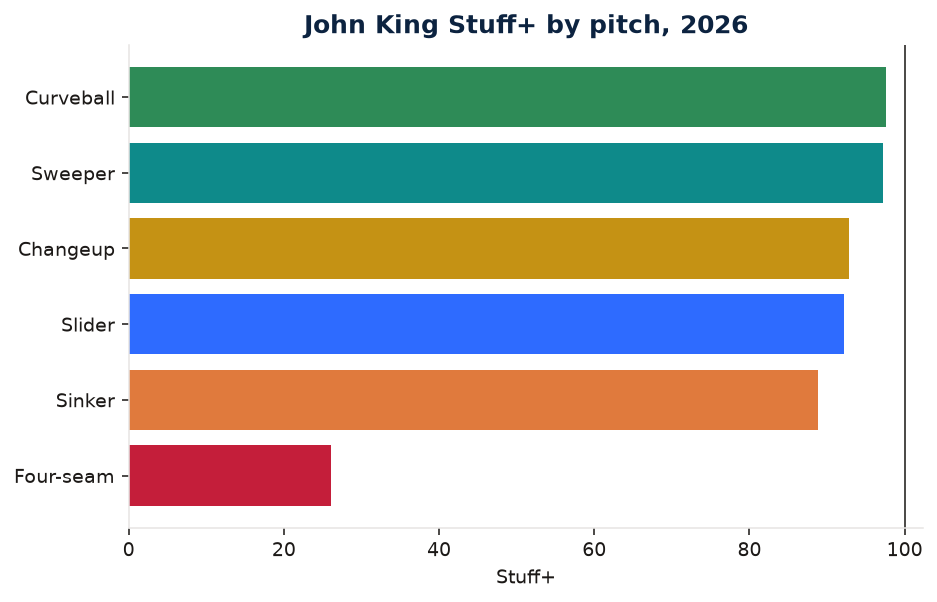

In [9]:
memo = json.loads((PROCESSED_DIR / "memo.json").read_text())
print(memo["player_name"], memo["season"], "Stuff+", round(memo["stuff_plus"], 1), "pitches", memo["pitches"])
print(
    f"Model RV/100 {memo['pred_rv_per_100']:.2f}, actual RV/100 {memo['actual_rv_per_100']:.2f}, "
    f"gap (actual minus model) {memo['gap_per_100']:.2f}"
)
arsenal = pd.DataFrame(memo["arsenal"])
show = arsenal[["pitch_type", "pitches", "usage", "velo", "ivb", "hb_arm", "vaa", "whiff_rate", "stuff_plus", "pred_rv", "actual_rv"]].copy()
show["pitch"] = show["pitch_type"].map(PITCH_NAMES)
show["usage"] = (show["usage"] * 100).round(1)
show["whiff_rate"] = (show["whiff_rate"] * 100).round(1)
show["stuff_plus"] = show["stuff_plus"].round(1)
show["pred_rv_per_100"] = (show["pred_rv"] * 100).round(2)
show["actual_rv_per_100"] = (show["actual_rv"] * 100).round(2)
display(show[["pitch", "pitches", "usage", "velo", "ivb", "hb_arm", "vaa", "whiff_rate", "stuff_plus", "pred_rv_per_100", "actual_rv_per_100"]].round(2))
for note in memo["suggestions"]:
    print("\n" + note["title"])
    print(note["detail"])
display(Image(filename=str(FIGURE_DIR / "stuff_vs_results.png")))
display(Image(filename=str(FIGURE_DIR / "marlins_movement.png")))
display(Image(filename=str(FIGURE_DIR / "marlins_stuff.png")))

## What this does not say

The grade is not a contract recommendation. It does not know health, it does not know the hitter, and a shape target is a comparison with pitches that already grade well, not an experiment. Closing a two-inch gap in sweep does not add a promised number of Stuff+ points. The usage-shift run estimate ignores the counts where the weaker pitch is already the right pitch. Sample size is on the reliability chart: below the stabilization point, the grade is a description of the pitches in hand, not a season talent number.